# 1、加载数据

In [2]:
import pandas as pd

df = pd.read_csv('top250_movie.csv',sep='#',encoding='utf8')
df.head()

,movie_num,movie_name,movie_year,movie_country,movie_type,movie_director,movie_assess,movie_score,movie_url,movie_intro
0,1,肖申克的救赎,1994,美国,犯罪 剧情,弗兰克·德拉邦特 Frank Darabont,1371845,9.6,https://movie.douban.com/subject/1292052/,希望让人自由。
1,2,霸王别姬,1993,中国大陆 香港,剧情 爱情 同性,陈凯歌 Kaige Chen,1014426,9.6,https://movie.douban.com/subject/1291546/,风华绝代。
2,3,这个杀手不太冷,1994,法国,剧情 动作 犯罪,吕克·贝松 Luc Besson,1254222,9.4,https://movie.douban.com/subject/1295644/,怪蜀黍和小萝莉不得不说的故事。
3,4,阿甘正传,1994,美国,剧情 爱情,罗伯特·泽米吉斯 Robert Zemeckis,1080698,9.4,https://movie.douban.com/subject/1292720/,一部美国近现代史。
4,5,美丽人生,1997,意大利,剧情 喜剧 爱情 战争,罗伯托·贝尼尼 Roberto Benigni,632080,9.5,https://movie.douban.com/subject/1292063/,最美的谎言。


# 2、查看数据基本信息

In [2]:
# 查看数据基本信息，查看各字段是否有缺失值
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
movie_num         250 non-null int64
movie_name        250 non-null object
movie_year        250 non-null object
movie_country     250 non-null object
movie_type        250 non-null object
movie_director    250 non-null object
movie_assess      250 non-null int64
movie_score       250 non-null float64
movie_url         250 non-null object
movie_intro       250 non-null object
dtypes: float64(1), int64(2), object(7)
memory usage: 19.6+ KB


# 3、重复值检查

In [3]:
df.duplicated().value_counts()
#检查是否有重名电影
len(df.movie_name.unique())

250

# 4、国家或者地区上榜数的排名情况

In [5]:
# 对于 country 列，有些电影由多个国家或地区联合制作
country =df['movie_country'].str.split(' ').apply(pd.Series)
print(country)

        0     1    2    3    4    5
0      美国   NaN  NaN  NaN  NaN  NaN
1    中国大陆    香港  NaN  NaN  NaN  NaN
2      法国   NaN  NaN  NaN  NaN  NaN
3      美国   NaN  NaN  NaN  NaN  NaN
4     意大利   NaN  NaN  NaN  NaN  NaN
5      美国   NaN  NaN  NaN  NaN  NaN
6      日本   NaN  NaN  NaN  NaN  NaN
7      美国   NaN  NaN  NaN  NaN  NaN
8      美国    英国  NaN  NaN  NaN  NaN
9      美国    英国  NaN  NaN  NaN  NaN
10     美国   NaN  NaN  NaN  NaN  NaN
11     印度   NaN  NaN  NaN  NaN  NaN
12    意大利   NaN  NaN  NaN  NaN  NaN
13     法国    瑞士   德国  NaN  NaN  NaN
14     美国   NaN  NaN  NaN  NaN  NaN
15     香港  中国大陆  NaN  NaN  NaN  NaN
16     美国    英国  加拿大   冰岛  NaN  NaN
17     日本   NaN  NaN  NaN  NaN  NaN
18     美国   NaN  NaN  NaN  NaN  NaN
19     韩国   NaN  NaN  NaN  NaN  NaN
20     香港   NaN  NaN  NaN  NaN  NaN
21     美国   NaN  NaN  NaN  NaN  NaN
22     美国   NaN  NaN  NaN  NaN  NaN
23     美国   NaN  NaN  NaN  NaN  NaN
24     法国   NaN  NaN  NaN  NaN  NaN
25     美国   NaN  NaN  NaN  NaN  NaN
26     美国    英国  NaN  NaN  N

In [6]:
#统计每个区域里相同国家的总数,将空值 NaN 替换为“0”
all_country = country.apply(pd.value_counts).fillna('0')
#print(all_country)

all_country.columns = ['area1','area2','area3','area4','area5','area6']
all_country['area1'] = all_country['area1'].astype(int)
all_country['area2'] = all_country['area2'].astype(int)
all_country['area3'] = all_country['area3'].astype(int)
all_country['area4'] = all_country['area4'].astype(int)
all_country['area5'] = all_country['area5'].astype(int)
all_country['area6'] = all_country['area6'].astype(int)
# 计算每个国家参与制作电影总数排名情况
all_country['all_counts'] = all_country['area1']+all_country['area2']+all_country['area3']+ \
all_country['area4']+all_country['area5']+all_country['area6']

#降序
all_country = all_country.sort_values(['all_counts'],ascending=False)
all_country.head(5)
#list(all_country.index)

,area1,area2,area3,area4,area5,area6,all_counts
美国,122,14,2,5,1,0,144
日本,31,2,0,0,0,0,33
英国,14,15,4,0,0,0,33
香港,19,8,0,0,0,0,27
法国,9,9,1,1,0,0,20


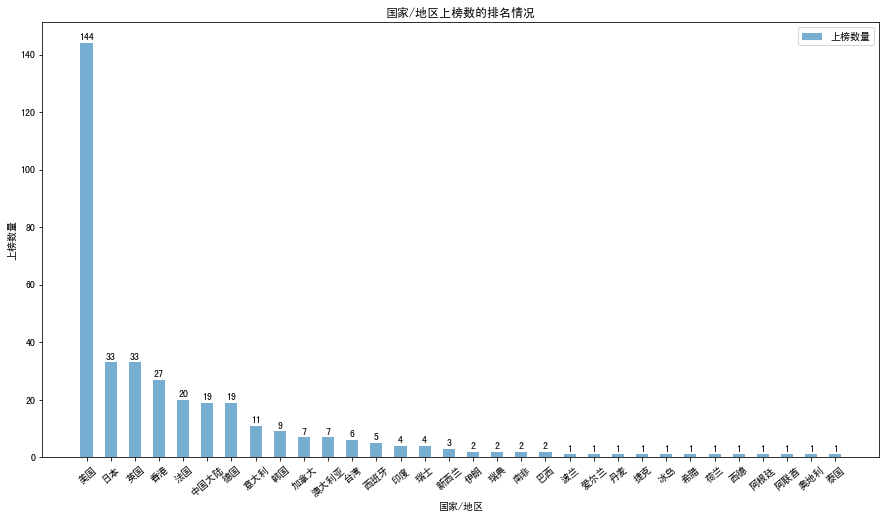

In [7]:
import matplotlib.pyplot as plt


# 创建画布
fig = plt.figure(figsize=(15, 8))

# 添加柱状图数值
for x, y in zip(range(len(all_country['all_counts'])),all_country['all_counts']):
    plt.text(x, y+1, str(y), ha='center') 


plt.title("国家/地区上榜数的排名情况")
plt.bar(all_country.index, all_country['all_counts'], width=0.5, alpha=0.6, lw=2, label='上榜数量')
plt.xticks( rotation=40)
plt.xlabel("国家/地区")
plt.ylabel("上榜数量")
plt.legend()
plt.show()

# 5、上榜电影类型排名 

In [20]:
all_type = df['movie_type'].str.split(' ').apply(pd.Series)
all_type = all_type.apply(pd.value_counts).fillna('0')
all_type.columns = ['tpye1','type2','type3','type4','type5']
all_type['tpye1'] = all_type['tpye1'].astype(int)
all_type['type2'] = all_type['type2'].astype(int)
all_type['type3'] = all_type['type3'].astype(int)
all_type['type4'] = all_type['type4'].astype(int)
all_type['type5'] = all_type['type5'].astype(int)
all_type.head(10)

all_type['all_counts'] = all_type['tpye1']+all_type['type2']+all_type['type3']+all_type['type4']+all_type['type5']

all_type = all_type.sort_values(['all_counts'],ascending=False)
all_type.head(10)

,tpye1,type2,type3,type4,type5,all_counts
剧情,162,22,5,0,0,189
爱情,3,39,18,0,0,60
喜剧,24,24,0,0,0,48
冒险,6,5,20,12,2,45
犯罪,12,23,7,3,0,45
奇幻,1,15,18,3,0,37
惊悚,0,7,15,11,2,35
动画,14,12,7,2,0,35
动作,17,12,3,0,0,32
悬疑,2,15,13,1,0,31


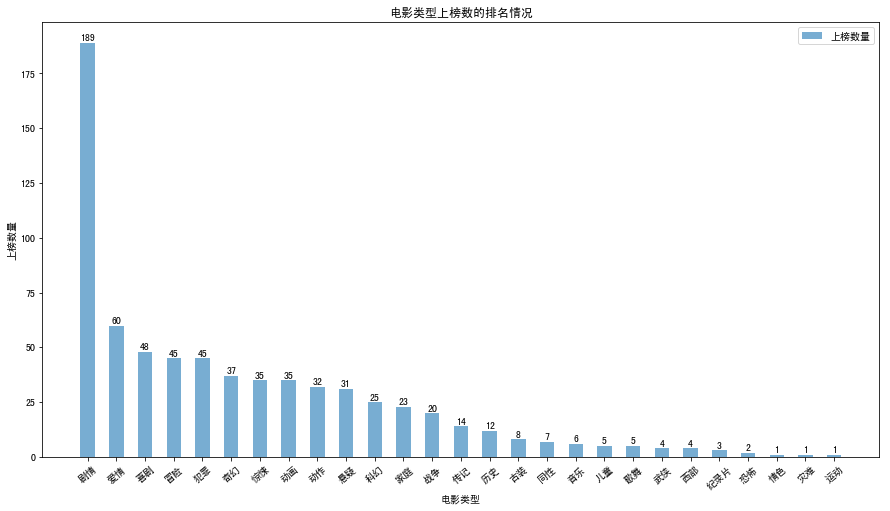

In [23]:
# 创建画布
fig = plt.figure(figsize=(15, 8))

# 添加柱状图数值
for x, y in zip(range(len(all_type['all_counts'])),all_type['all_counts']):
    plt.text(x, y+1, str(y), ha='center') 


plt.title("电影类型上榜数的排名情况")
plt.bar(all_type.index, all_type['all_counts'], width=0.5, alpha=0.6, lw=2, label='上榜数量')
plt.xticks( rotation=40)
plt.xlabel("电影类型")
plt.ylabel("上榜数量")
plt.legend()
plt.show()

# 6、上榜次数最多的导演

 克里斯托弗·诺兰 Christopher Nolan    7
 宫崎骏 Hayao Miyazaki            7
 王家卫 Kar Wai Wong              5
 史蒂文·斯皮尔伯格 Steven Spielberg    5
 李安 Ang Lee                    4
Name: movie_director, dtype: int64


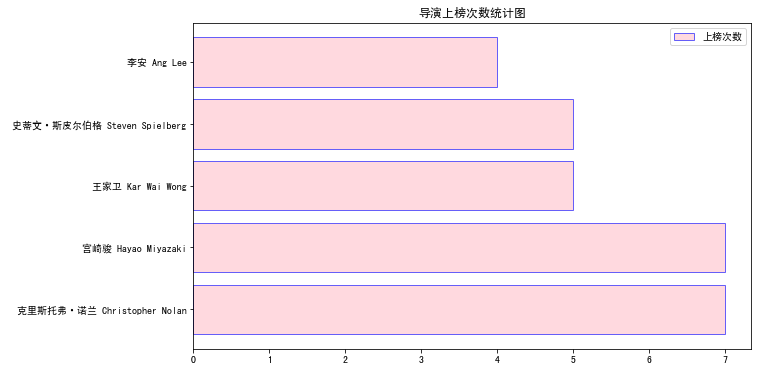

In [36]:
# value_counts()返回一个Series 序列
director = df['movie_director'].value_counts()[0:5]

# 创建画布
fig = plt.figure(figsize=(10, 6))

# 绘制图形
plt.title('导演上榜次数统计图')
plt.barh(director.index, director.values, alpha=0.6, facecolor = 'pink', edgecolor = 'blue', label='上榜次数')
plt.legend()
plt.show()

# 7、评分和排名的关系

-0.7171361414557139

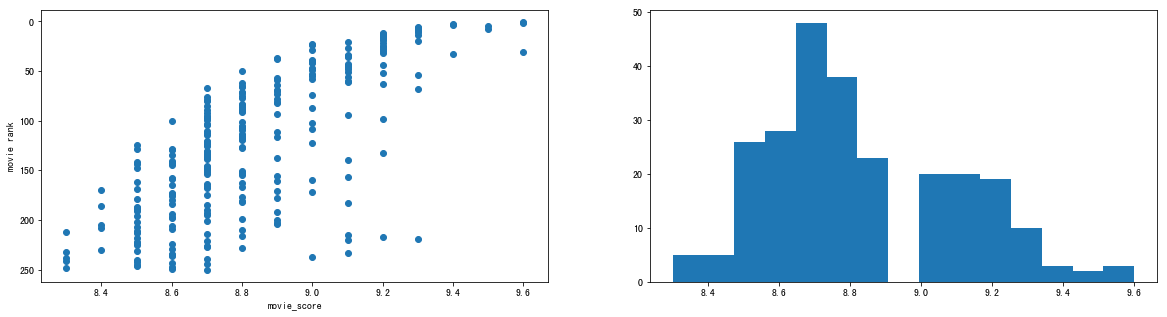

In [8]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.scatter(df['movie_score'],df['movie_num'])
plt.xlabel('movie_score')
plt.ylabel('movie rank')
#修改y轴为倒序
plt.gca().invert_yaxis()

#集中趋势的直方图
plt.subplot(1,2,2)
plt.hist(df['movie_score'],bins=15)

#电影排名和评分的相关性检测
df['movie_score'].corr(df['movie_num'])
#out[35]:-0.69237508495035771

# 评分大多是集中在 8.3 - 9.2 之间，随评分的升高，豆瓣Top250排名名次也提前,Pearson相关系数为-0.6923，为强相关性